# Section 4 — Out-of-Sample Portfolio Risk Management Backtest

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq

DATA = Path('research_data')
DATA.mkdir(exist_ok=True)

p_train = pd.read_csv(DATA / 'portfolio_train_simple_returns.csv', index_col=0, parse_dates=True).iloc[:, 0]
p_test = pd.read_csv(DATA / 'portfolio_test_simple_returns.csv', index_col=0, parse_dates=True).iloc[:, 0]
f = pd.read_csv(DATA / 'portfolio_fitted_models_2021_2023.csv').iloc[0]

## 1. Pre-commit risk settings

In [2]:
TARGET_VAR = 0.01
ROLL_WINDOW = 63
MAX_EXPOSURE = 1.0
COST_RATE = 0.0005
ALPHA = 0.01
TRAIN_SD = float(f.training_sd_pct) / 100

## 2. Model-specific 1% quantiles from frozen training fits

In [3]:
q_normal = stats.norm.ppf(ALPHA, loc=f.normal_mu_pct, scale=f.normal_sd_pct) / 100
q_t = stats.t.ppf(ALPHA, df=f.t_df, loc=f.t_loc_pct, scale=f.t_scale_pct) / 100

def gmm_cdf(v):
    return f.gmm_weight_1 * stats.norm.cdf(v, loc=f.gmm_mean_1_pct, scale=f.gmm_sd_1_pct) + f.gmm_weight_2 * stats.norm.cdf(v, loc=f.gmm_mean_2_pct, scale=f.gmm_sd_2_pct)

q_gmm = brentq(lambda z: gmm_cdf(z) - ALPHA, -100, 100) / 100
QUANTILES = {'Normal': q_normal, 'Student-t': q_t, 'GMM': q_gmm}
print('Training-fitted 1% portfolio return quantiles:', QUANTILES)

Training-fitted 1% portfolio return quantiles: {'Normal': np.float64(-0.038563245031206), 'Student-t': np.float64(-0.042979349694094414), 'GMM': -0.039645279189281755}


## 3. Build strictly lagged daily volatility estimates

In [4]:
all_r = pd.concat([p_train, p_test])
lagged_vol = all_r.shift(1).rolling(ROLL_WINDOW, min_periods=ROLL_WINDOW).std(ddof=0).loc[p_test.index]
assert lagged_vol.notna().all(), 'Insufficient prior observations'
vol_multiplier = (lagged_vol / TRAIN_SD).clip(lower=0.25, upper=4.0)

print('Volatility multiplier:', vol_multiplier.describe())

Volatility multiplier: count    502.000000
mean       0.782534
std        0.277484
min        0.470370
25%        0.601102
50%        0.692881
75%        0.842248
max        1.509036
Name: portfolio_return, dtype: float64


## 4. Determine exposure before observing the next return

In [5]:
def scaled_quantile(q, model, mult):
    mean = (f.normal_mu_pct if model == 'Normal' else f.t_loc_pct if model == 'Student-t' else f.gmm_weight_1 * f.gmm_mean_1_pct + f.gmm_weight_2 * f.gmm_mean_2_pct) / 100
    return mean + mult * (q - mean)

exposures = pd.DataFrame(index=p_test.index)
exposures['Fixed 100%'] = 1.0

for model, q in QUANTILES.items():
    forecast_var = (-scaled_quantile(q, model, vol_multiplier)).clip(lower=1e-08)
    exposures[model] = (TARGET_VAR / forecast_var).clip(lower=0, upper=MAX_EXPOSURE)

display(exposures.head())


,Fixed 100%,Normal,Student-t,GMM
Date,,,,
2024-01-02,1.0,0.465671,0.417160,0.452610
2024-01-03,1.0,0.465454,0.416966,0.452399
2024-01-04,1.0,0.470256,0.421252,0.457058
2024-01-05,1.0,0.473376,0.424036,0.460085
2024-01-08,1.0,0.470069,0.421085,0.456876


## 5. Realized daily net P&L and wealth curves

Date,Ending wealth
Fixed 100%,1.916017
Normal,1.241652
Student-t,1.214896
GMM,1.234461


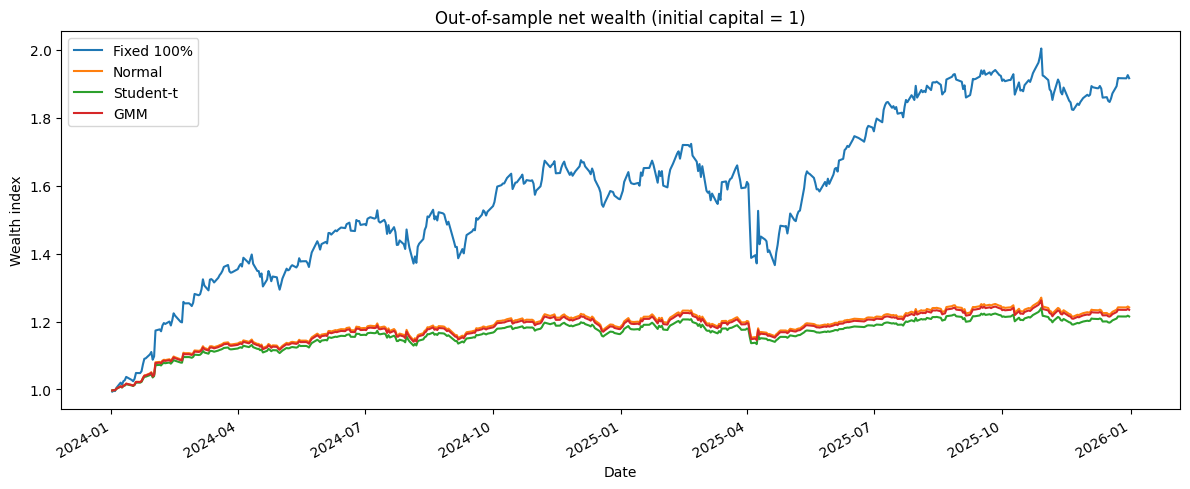

In [6]:
daily_gross = exposures.mul(p_test, axis=0)
turnover = exposures.diff().abs()
turnover.iloc[0] = exposures.iloc[0].abs()
daily_net = daily_gross - COST_RATE * turnover
wealth = (1 + daily_net).cumprod()

display(wealth.tail(1).T.rename(columns={wealth.index[-1]: 'Ending wealth'}))

ax = wealth.plot(figsize=(12, 5), title='Out-of-sample net wealth (initial capital = 1)')
ax.set_ylabel('Wealth index')

plt.tight_layout()
plt.show()

## 6. Compare returns, downside risk, drawdowns, and turnover

In [7]:
def performance(series, turn):
    wealth = (1 + series).cumprod()
    peak = wealth.cummax()
    drawdown = wealth / peak - 1
    q = np.quantile(series, 0.01)
    return {'total_return': wealth.iloc[-1] - 1, 
            'annualized_vol': series.std(ddof=0) * np.sqrt(252), 
            'max_drawdown': drawdown.min(), 
            'realized_99pct_loss': -q, 
            'realized_ES_99pct': -series[series <= q].mean(), 
            'annualized_sharpe_zero_cash': np.sqrt(252) * series.mean() / series.std(ddof=0) if series.std(ddof=0) > 0 else np.nan, 
            'average_exposure': exposures[series.name].mean(), 
            'total_exposure_turnover': turn.sum(), 
            'estimated_total_cost_frac': COST_RATE * turn.sum()
            }

report = pd.DataFrame({name: performance(daily_net[name], turnover[name]) for name in daily_net}).T
print('Performance comparison:')

display(report.round(4))

report.to_csv(DATA / 'portfolio_strategy_performance.csv')
exposures.to_csv(DATA / 'portfolio_strategy_exposures.csv')
daily_net.to_csv(DATA / 'portfolio_strategy_daily_net_returns.csv')

Performance comparison:


,total_return,annualized_vol,max_drawdown,realized_99pct_loss,realized_ES_99pct,annualized_sharpe_zero_cash,average_exposure,total_exposure_turnover,estimated_total_cost_frac
Fixed 100%,0.9160,0.2277,-0.2072,0.0391,0.0545,1.5479,1.0000,1.0000,0.0005
Normal,0.2417,0.0800,-0.0678,0.0138,0.0180,1.3987,0.3698,3.1061,0.0016
Student-t,0.2149,0.0717,-0.0609,0.0124,0.0162,1.3992,0.3315,2.7765,0.0014
GMM,0.2345,0.0778,-0.0660,0.0135,0.0175,1.3989,0.3596,3.0158,0.0015


## 7. Interpret with limitations

- The 2024–2025 period is one market regime; a superior result is not proof of a persistent trading edge.
- Common lagged volatility scaling changes the fixed-parameter model into a conditional **heuristic**; report this explicitly.
- Cash yield, taxes, slippage beyond the assumed turnover cost, and daily constituent rebalancing costs are excluded.
- Higher performance may come from exposure differences rather than a better probability distribution. Compare average exposure and drawdowns alongside return.
- A risk forecast can improve calibration without increasing returns; this is a meaningful finding.